In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Laeb andmestiku
df = pd.read_csv(
    "weather_dataset_2024_2026.csv",
    parse_dates=["time"]
)

# Andmestiku suurus
print("Dataset shape:", df.shape)

# Esimesed read
display(df.head())

# Veergude tüübid
df.info()

# Puuduvad väärtused
print("\nMissing values:")
print(df.isna().sum())

# Duplikaadid
print("\nDuplicate timestamps:", df["time"].duplicated().sum())

Dataset shape: (6624, 13)


,time,actual_temperature,actual_precipitation,actual_wind_speed,temperature_ECMWF,temperature_GFS,temperature_ICON_EU,precipitation_ECMWF,precipitation_GFS,precipitation_ICON_EU,wind_speed_ECMWF,wind_speed_GFS,wind_speed_ICON_EU
0,2024-06-01 00:00:00,17.4,0.0,0.8,17.2,15.5,17.4,0.0,1.0,0.0,1.90,2.66,1.04
1,2024-06-01 01:00:00,17.1,0.0,1.2,16.4,15.6,16.5,0.0,0.0,0.0,1.30,2.19,1.13
2,2024-06-01 02:00:00,15.3,0.0,1.3,16.0,15.5,16.0,0.0,0.0,0.0,0.90,1.71,1.08
3,2024-06-01 03:00:00,14.5,0.0,0.7,16.2,15.1,15.6,0.3,0.0,0.0,1.03,2.18,1.00
4,2024-06-01 04:00:00,14.5,0.0,0.9,16.8,15.0,15.3,0.3,0.0,0.0,1.63,2.48,0.61


<class 'pandas.DataFrame'>
RangeIndex: 6624 entries, 0 to 6623
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   time                   6624 non-null   datetime64[us]
 1   actual_temperature     6624 non-null   float64       
 2   actual_precipitation   6624 non-null   float64       
 3   actual_wind_speed      6624 non-null   float64       
 4   temperature_ECMWF      6624 non-null   float64       
 5   temperature_GFS        6624 non-null   float64       
 6   temperature_ICON_EU    6624 non-null   float64       
 7   precipitation_ECMWF    6624 non-null   float64       
 8   precipitation_GFS      6624 non-null   float64       
 9   precipitation_ICON_EU  6624 non-null   float64       
 10  wind_speed_ECMWF       6624 non-null   float64       
 11  wind_speed_GFS         6624 non-null   float64       
 12  wind_speed_ICON_EU     6624 non-null   float64       
dtypes: datetime64[

In [2]:
actual_columns = [
    "actual_temperature",
    "actual_precipitation",
    "actual_wind_speed"
]

df[actual_columns].describe()

,actual_temperature,actual_precipitation,actual_wind_speed
count,6624.000000,6624.000000,6624.000000
mean,17.116108,0.133348,2.341063
std,4.237208,0.851225,1.337955
min,5.200000,0.000000,0.100000
25%,14.100000,0.000000,1.300000
50%,16.800000,0.000000,2.200000
75%,19.900000,0.000000,3.200000
max,31.600000,24.100000,8.400000


In [3]:
df["year"] = df["time"].dt.year

yearly_stats = df.groupby("year")[actual_columns].mean()

display(yearly_stats.round(2))

,actual_temperature,actual_precipitation,actual_wind_speed
year,,,
2024,17.91,0.14,2.17
2025,16.49,0.14,2.53
2026,16.95,0.12,2.33


**Observations:** 
The dataset contains 6,624 hourly observations from the summers of 2024–2026. The average temperature was 17.12°C, the average precipitation was 0.13 mm/h, and the average wind speed was 2.34 m/s.

The summer of 2024 was the warmest, while 2025 was the coolest and windiest. Precipitation was highly unevenly distributed, with at least 75% of the hours recording no precipitation. This may create a class imbalance when developing precipitation classification models.

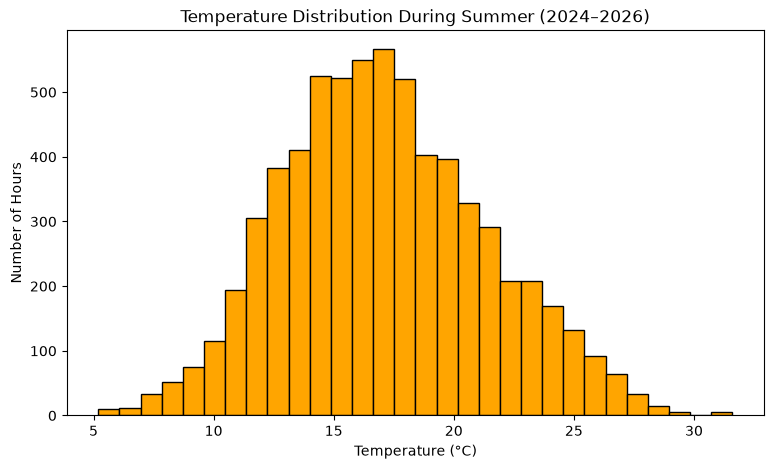

In [4]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["actual_temperature"],
    bins=30,
    color="orange",
    edgecolor="black"
)

plt.title("Temperature Distribution During Summer (2024–2026)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of Hours")

plt.show()

**Observations**
The temperature distribution is approximately bell-shaped, with most observations between 14°C and 19°C. The highest frequency occurs around 16–17°C. Extreme temperatures were relatively rare, ranging from a minimum of 5.2°C to a maximum of 31.6°C.

Rainy hours: 680
Dry hours: 5944
Rainy hours percentage: 10.27%


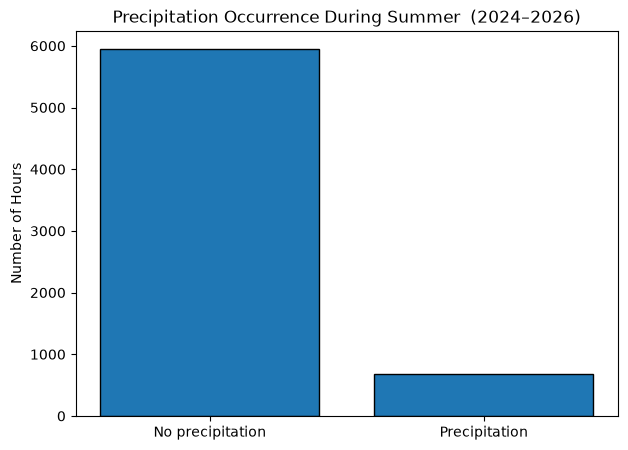

In [5]:
# Sademetega ja sademeteta tunnid
rainy = (df["actual_precipitation"] > 0).sum()
dry = (df["actual_precipitation"] == 0).sum()

print("Rainy hours:", rainy)
print("Dry hours:", dry)
print(f"Rainy hours percentage: {rainy / len(df) * 100:.2f}%")

# Graafik
plt.figure(figsize=(7, 5))

plt.bar(
    ["No precipitation", "Precipitation"],
    [dry, rainy],
    edgecolor="black"
)

plt.title("Precipitation Occurrence During Summer  (2024–2026)")
plt.ylabel("Number of Hours")

plt.show()

**Observations:**
Precipitation occurred during only 680 out of 6,624 hours (10.27%), while 89.73% of the hours had no precipitation. This indicates a significant class imbalance, which should be considered when evaluating precipitation classification models. Accuracy alone may be misleading, so precision, recall, and F1-score will also be used.

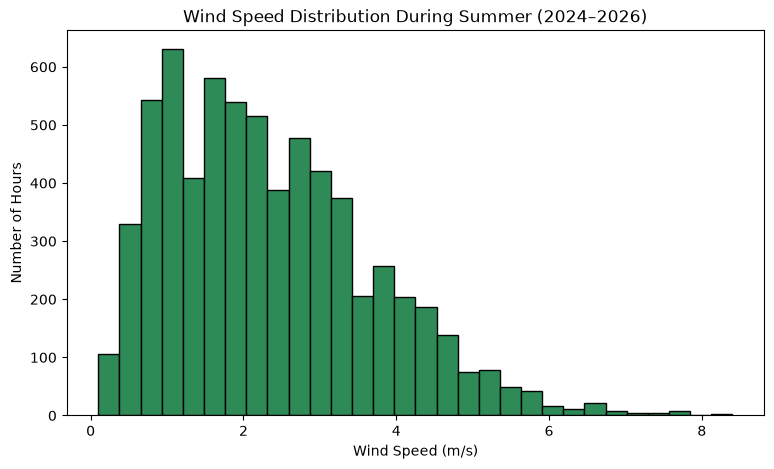

In [6]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["actual_wind_speed"],
    bins=30,
    color="seagreen",
    edgecolor="black"
)

plt.title("Wind Speed Distribution During Summer (2024–2026)")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Number of Hours")

plt.show()

**Observations:**
The wind speed distribution is right-skewed, with most observations between 1 and 3 m/s. Wind speeds above 5 m/s were relatively uncommon. The average wind speed was 2.34 m/s, while the maximum recorded wind speed was 8.4 m/s.

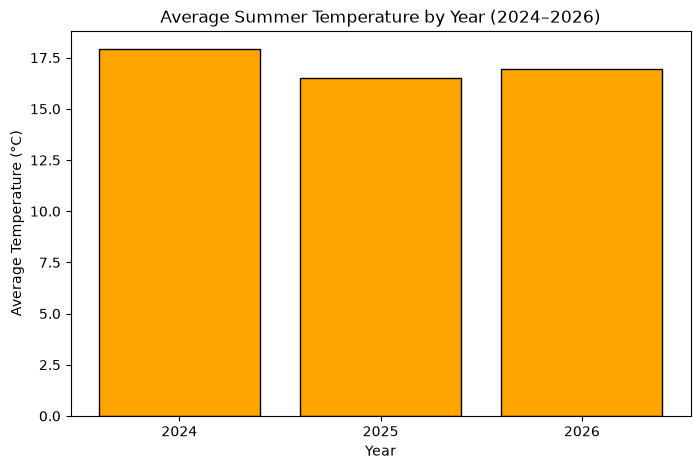

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(
    yearly_stats.index.astype(str),
    yearly_stats["actual_temperature"],
    color="orange",
    edgecolor="black"
)

plt.title("Average Summer Temperature by Year (2024–2026)")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")

plt.show()

**Observations:**
The summer of 2024 had the highest average temperature (17.91°C), while 2025 was the coolest (16.49°C). The average temperature in 2026 was 16.95°C. These differences provide an opportunity to investigate whether weather forecast accuracy varies between years.

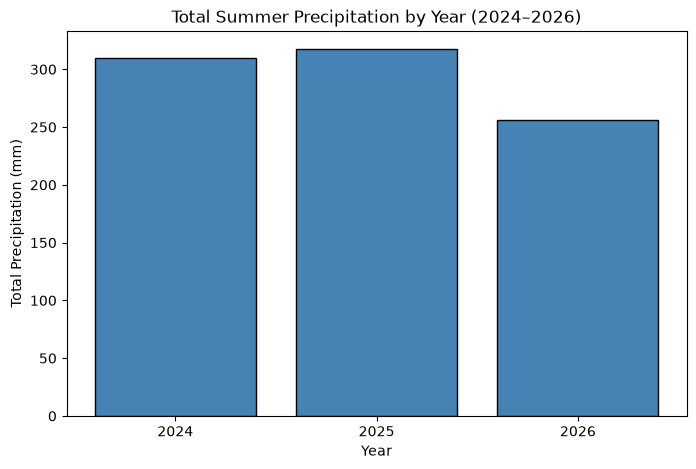

In [8]:
yearly_rain = df.groupby("year")["actual_precipitation"].sum()

plt.figure(figsize=(8, 5))

plt.bar(
    yearly_rain.index.astype(str),
    yearly_rain,
    color="steelblue",
    edgecolor="black"
)

plt.title("Total Summer Precipitation by Year (2024–2026)")
plt.xlabel("Year")
plt.ylabel("Total Precipitation (mm)")

plt.show()

**Observations:**
The summer of 2025 had the highest total precipitation (approximately 317 mm), while 2026 had the lowest (approximately 256 mm). The summer of 2024 had a similar precipitation total to 2025.

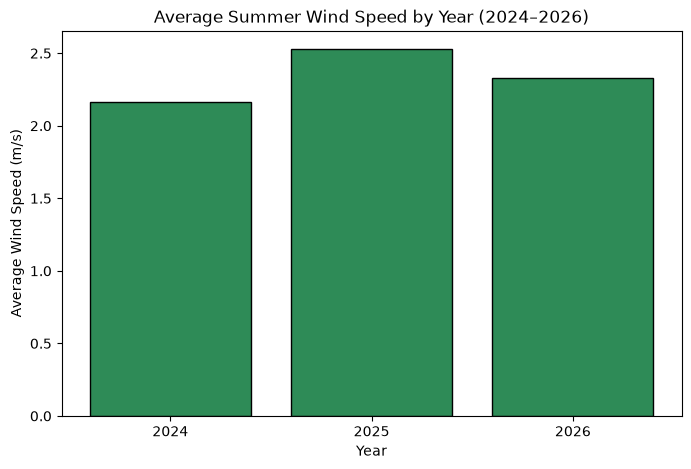

In [9]:
plt.figure(figsize=(8, 5))

plt.bar(
    yearly_stats.index.astype(str),
    yearly_stats["actual_wind_speed"],
    color="seagreen",
    edgecolor="black"
)

plt.title("Average Summer Wind Speed by Year (2024–2026)")
plt.xlabel("Year")
plt.ylabel("Average Wind Speed (m/s)")

plt.show()

**Observations:** The average wind speed was also highest in 2025 (2.53 m/s) and lowest in 2024 (2.17 m/s). These differences provide an opportunity to investigate whether weather forecasting models perform differently under varying weather conditions.